Вспомогательные функции из лекции

In [9]:
import math
def bisection(f, a, b, eps=1e-9, max_iter=200):
    """
    Метод половинного деления с журналом итераций.

    Возвращает: (корень, журнал, статус)
    статус = 'ok' — достигнута точность по длине интервала
    статус = 'f_zero' — f(c) == 0 (точное попадание)
    статус = 'max_iter' — исчерпан лимит итераций
    """

    fa, fb = f(a), f(b)
    if fa * fb > 0:
        raise ValueError(f"Нет смены знака на [{a}, {b}]: f(a)={fa}, f(b)={fb}")

    journal = [] # список словарей — каждая запись = одна итерация

    for k in range(1, max_iter + 1):
        c = (a + b) / 2
        fc = f(c)
        length = b - a
        # записываем всё, что нужно для аудита
        journal.append({"iter": k, "a": a, "b": b, "c": c, "f(c)": fc, "length": length,})

        # условия остановки
        if fc == 0:
            return c, journal, "f_zero"
        if length < eps:
            return c, journal, "ok"

        # обновляем интервал
        if fa * fc < 0:
            b = c
            fb = fc
        else:
            a = c
            fa = fc

    return c, journal, "max_iter"

def print_journal(journal, title=""):
    if title:
        print(f"\n=== {title} ===")
        print(f"{'k':>3} | {'a':>12} | {'b':>12} | {'c':>12} | "
        f"{'f(c)':>14} | {'b-a':>10}")
    print("-" * 80)
    for row in journal:
        print(f"{row['iter']:>3} | {row['a']:>12.6f} | {row['b']:>12.6f} | "
        f"{row['c']:>12.6f} | {row['f(c)']:>14.3e} | "
        f"{row['length']:>10.2e}")



## Задача 1
Дана функция f(x) = x³ − 6x² + 11x − 6

### 1) График на отрезке [0; 4]

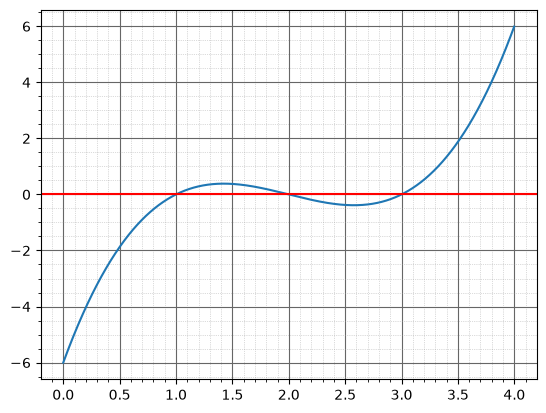

In [10]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(0.0, 4, 0.001)
y = x**3 - 6*x**2 + 11*x - 6

ax = plt.subplot()
ax.minorticks_on() # мелкие деления что бы лучше видеть границы где нахождится корень

ax.plot(x, y)

# 2. Настраиваем сетку для основных (больших) делений
ax.grid(which='major', color='#666666', linestyle='-', linewidth=0.8)

# 3. Настраиваем сетку для вспомогательных (внутренних) делений
ax.grid(which='minor', color='#999999', linestyle=':', linewidth=0.5, alpha=0.7)

# Красная горизонтальная линия на уровне y = 0
ax.axhline(0, color='red', linewidth=1.5)

plt.show()


Для каждого интервала примените bisection с точностью ε = 1e-9
Хоть по графику и видно точные корни, я взял немного кривые интервалы что бы они не находились точно
1) [-0.9; 1.2]
2) [1.8; 2.3]
3) [2.9; 3.2]


In [ ]:
f = lambda x: x**3 - 6*x**2 + 11*x - 6

a,b = -0.9, 1.2
x1, j1, s1 = bisection(f, a, b, eps=1e-9)
print_journal(j1, f"f(x) = x³ − 6x² + 11x − 6 [{a}; {b}]")
print(f"корень: {x1:.12f}, f(x1) = {f(x1):.3e}, статус: {s1}")
print(f"итераций: {len(j1)}")




=== f(x) = x³ − 6x² + 11x − 6 [-0.9; 1.2] ===
  k |            a |            b |            c |           f(c) |        b-a
--------------------------------------------------------------------------------
  1 |    -0.900000 |     1.200000 |     0.150000 |     -4.482e+00 |   2.10e+00
  2 |     0.150000 |     1.200000 |     0.675000 |     -1.001e+00 |   1.05e+00
  3 |     0.675000 |     1.200000 |     0.937500 |     -1.370e-01 |   5.25e-01
  4 |     0.937500 |     1.200000 |     1.068750 |      1.236e-01 |   2.62e-01
  5 |     0.937500 |     1.068750 |     1.003125 |      6.221e-03 |   1.31e-01
  6 |     0.937500 |     1.003125 |     0.970313 |     -6.205e-02 |   6.56e-02
  7 |     0.970313 |     1.003125 |     0.986719 |     -2.709e-02 |   3.28e-02
  8 |     0.986719 |     1.003125 |     0.994922 |     -1.023e-02 |   1.64e-02
  9 |     0.994922 |     1.003125 |     0.999023 |     -1.956e-03 |   8.20e-03
 10 |     0.999023 |     1.003125 |     1.001074 |      2.145e-03 |   4.10e-03
 11

In [12]:
a,b = 1.8, 2.3
x1, j1, s1 = bisection(f, a, b, eps=1e-9)
print_journal(j1, f"f(x) = x³ − 6x² + 11x − 6 [{a}; {b}]")
print(f"корень: {x1:.12f}, f(x1) = {f(x1):.3e}, статус: {s1}")
print(f"итераций: {len(j1)}")




=== f(x) = x³ − 6x² + 11x − 6 [1.8; 2.3] ===
  k |            a |            b |            c |           f(c) |        b-a
--------------------------------------------------------------------------------
  1 |     1.800000 |     2.300000 |     2.050000 |     -4.988e-02 |   5.00e-01
  2 |     1.800000 |     2.050000 |     1.925000 |      7.458e-02 |   2.50e-01
  3 |     1.925000 |     2.050000 |     1.987500 |      1.250e-02 |   1.25e-01
  4 |     1.987500 |     2.050000 |     2.018750 |     -1.874e-02 |   6.25e-02
  5 |     1.987500 |     2.018750 |     2.003125 |     -3.125e-03 |   3.12e-02
  6 |     1.987500 |     2.003125 |     1.995312 |      4.687e-03 |   1.56e-02
  7 |     1.995312 |     2.003125 |     1.999219 |      7.812e-04 |   7.81e-03
  8 |     1.999219 |     2.003125 |     2.001172 |     -1.172e-03 |   3.91e-03
  9 |     1.999219 |     2.001172 |     2.000195 |     -1.953e-04 |   1.95e-03
 10 |     1.999219 |     2.000195 |     1.999707 |      2.930e-04 |   9.77e-04
 11 

In [13]:
a,b = 2.9, 3.2
x1, j1, s1 = bisection(f, a, b, eps=1e-9)
print_journal(j1, f"f(x) = x³ − 6x² + 11x − 6 [{a}; {b}]")
print(f"корень: {x1:.12f}, f(x1) = {f(x1):.3e}, статус: {s1}")
print(f"итераций: {len(j1)}")


=== f(x) = x³ − 6x² + 11x − 6 [2.9; 3.2] ===
  k |            a |            b |            c |           f(c) |        b-a
--------------------------------------------------------------------------------
  1 |     2.900000 |     3.200000 |     3.050000 |      1.076e-01 |   3.00e-01
  2 |     2.900000 |     3.050000 |     2.975000 |     -4.814e-02 |   1.50e-01
  3 |     2.975000 |     3.050000 |     3.012500 |      2.547e-02 |   7.50e-02
  4 |     2.975000 |     3.012500 |     2.993750 |     -1.238e-02 |   3.75e-02
  5 |     2.993750 |     3.012500 |     3.003125 |      6.279e-03 |   1.88e-02
  6 |     2.993750 |     3.003125 |     2.998437 |     -3.118e-03 |   9.38e-03
  7 |     2.998437 |     3.003125 |     3.000781 |      1.564e-03 |   4.69e-03
  8 |     2.998437 |     3.000781 |     2.999609 |     -7.808e-04 |   2.34e-03
  9 |     2.999609 |     3.000781 |     3.000195 |      3.907e-04 |   1.17e-03
 10 |     2.999609 |     3.000195 |     2.999902 |     -1.953e-04 |   5.86e-04
 11 

## Вывод
Число итераций примерно соответсвует log2(Δ / ε) в идеале должно быть 29, у меня получилось 30   (math.log2(0.3/1e-9)=28.16)


## Задача 2. Бисекция для уравнения с параметром

Условие. Рассмотрите уравнение f(x) = cos x − kx = 0, где k > 0 — параметр. Это
уравнение возникает в задачах о равновесии маятника с трением.
1. Для k = 0.5 локализуйте корень на отрезке [0, 2] (проверьте смену знака).
Примените бисекцию с ε = 10−9, выведите журнал.
